# Differential gene expression: thousands of comparisons

<div>
<img src="Images/Asthma_airways.png" width='50%' title=""/>
</div>

Researchers wanted to better understand how the steroid, dexamethasone, suppresses inflammation in the lungs of people with asthma. They did this by identifying which genes of airway smooth muscle cells were differentially expressed when treated with dexamethasone. RNA-Seq, a high-throughput sequencing method, was used to quantify transcriptomic changes in thousands of genes.

## Imports

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

## Load and print the data

First we read in the dataset and print it to see how it looks and what the variable names, types and values are.

In [12]:
rna = pd.read_csv('../Datasets/airway_merged_data_cleaned.csv')
rna.head(10)

,gene_id,dex,cell_line,count
0,E000003,treated,S09,448
1,E000003,treated,S13,408
2,E000003,treated,S17,1047
3,E000003,treated,S21,572
4,E000003,untreated,S08,679
5,E000003,untreated,S12,873
6,E000003,untreated,S16,1138
7,E000003,untreated,S20,770
8,E000419,treated,S09,515
9,E000419,treated,S13,365


There are four variables:

1. `gene_id`: The ID of the gene. We need this to group counts together for each gene.
2. `dex`: An explanatory categorical variable with two levels `treated` and `untreated` with dexamethasone.
3. `cell_line`: The ID of the airway smooth muscle cell line. This is not actually needed for the analysis.
4. `count`: The number of RNA short read sequences of the gene in a particular cell line. The higher the count the more the gene is expressed in that cell line.

Let's print out how many unique values there are for each variable.

In [14]:
for c in rna.columns:
    print(c, rna[c].nunique())

gene_id 25403
dex 2
cell_line 8
count 9162


We have 25,403 unique genes. Two treatments for each gene: `treated` and `untreated`. The researchers used 8 cell lines, four for the treated cells and four for the untreated cells. So for each gene we have four short read counts in untreated cell lines and four short read counts in treated cell lines.

If dexamethasone increases a gene's expression then the mean number of RNA short read counts will be high in the treated cell lines and low in the untreated cell lines. On the other hand, if dexamethasone decreases a gene's expression then the mean number of RNA short read counts will be low in the treated cell lines and high in the untreated cell lines. Finally if dexamethasone does not change a gene expression the means in the treated and untreated cell lines will be similar.

What we want for each gene is a significance test on whether the difference in the mean read counts between treated and untreated cell lines is compatible with the null hypothesis of no difference. As we are comparing means we use a two-sample *t*-test on each gene. So that's 25,403 *t*-tests altogether. 

If dexamethasone really had no effect on expression of any gene we would expect 25,403 x 0.05 = 1,207 false positives. However, the researchers do expect dexamethasone to change the expression of some genes, and these should, hopefully, have significant *P*-values. The purpose of adjusting *P*-values for multiple testing is to filter out as many false positives as possible, leaving just a handful of genes that researchers can focus their attention on.

# Plot RNA read counts

As always, we plot the numerical data to see what it looks like. There's a lot of data so this may take some time.

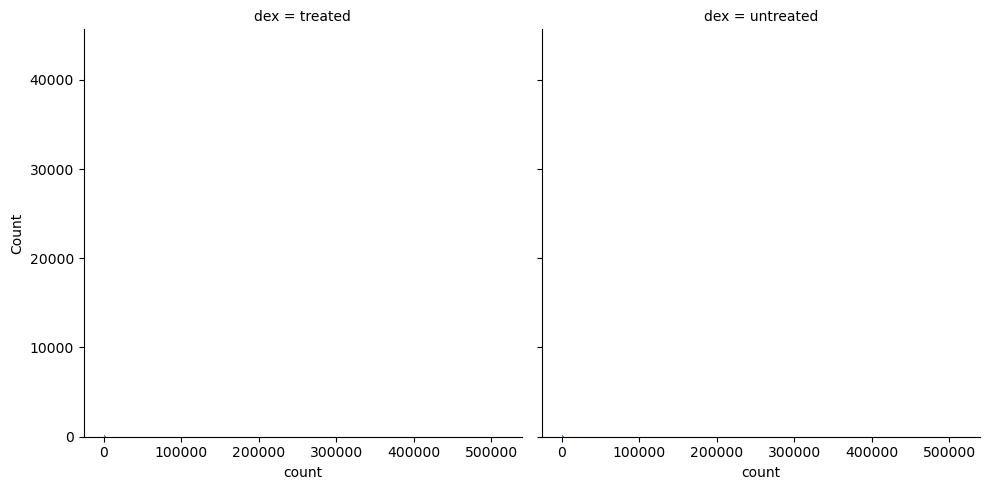

In [85]:
sns.displot(data=rna, x='count', col='dex');

There's clearly something strange going on with the RNA read counts as the plots are empty. Let's use `describe()` to have a look at some descriptive statistics of `count`.

In [19]:
rna['count'].describe()

count    203224.000000
mean        863.290369
std        6209.391040
min           0.000000
25%           3.000000
50%          45.000000
75%         489.000000
max      513766.000000
Name: count, dtype: float64

This explains why the histograms didn't work. The mean read count is 863, but the standard deviation is almost ten times larger at 6209. Moreover, the maximum read count is 513,766.

This tells us the data are highly skewed and vary over five orders of magnitude.

In this case we should log-transform the read counts. But there's a problem; some read counts are zero, and the log of zero is infinity. We can't do an analysis with data that contains infinities. 

The trick is to add 1 to all read counts. So any count of zero becomes 1, and the log of 1 is zero.

While adding 1 is common for exploratory visualizations, as we're doing here, it is generally discouraged for formal differential expression analysis. Specialized statistical packages like DESeq2 and edgeR should be used instead.

Let's add 1 to all counts, take log base 2 and replot. Why base 2? That will become clearer in a moment.

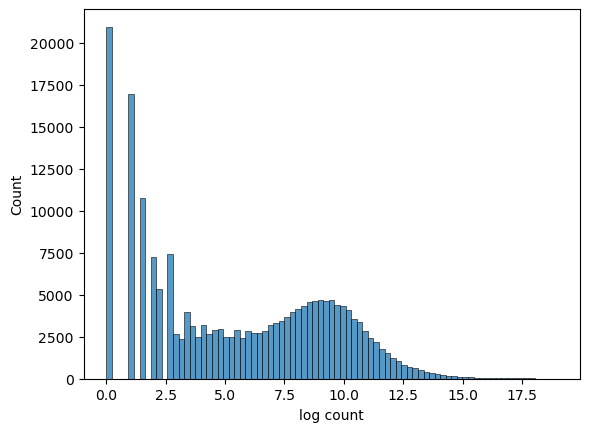

In [21]:
rna['log count'] = np.log2(rna['count'] + 1)
sns.histplot(rna['log count']);

## Perform a *t*-test for each gene

We first have to perform *t*-tests on all 25,403 genes. To code this we create a loop that loops through all genes one at a time. Inside the loop we perform a significance *t*-test to determine if the difference in the means of log read counts between treated and untreated cell lines is compatible with the null hypothesis of no difference.  The loop stores the resulting *P*-value of the test in a dictionary along with the gene's ID.

After finishing with all genes, we convert the dictionary of saved results into a pandas DataFrame as that is easier to manipulate than a dictionary.

In [23]:
# set up a dictionary to save the results of the t-tests for all genes
results = {'gene_id': [], 'p_raw': []}

# group the data into genes
genes = rna.groupby('gene_id')

# loop through each gene
for gene_id, gene in genes:

    # get the log2 counts for the four treated and the four untreated cell lines
    trt_counts = gene[gene['dex'] == 'treated']['log count']
    untrt_counts = gene[gene['dex'] == 'untreated']['log count']

    # perform a t-test to compare the means of the treated and untreated cell lines
    test = ttest_ind(trt_counts, untrt_counts)

    # store the gene_id and raw p-value from the t-test in the results dictionary
    results['gene_id'].append(gene_id)
    results['p_raw'].append(test.pvalue)

# convert the results dictionary to a pandas DataFrame for easier analysis
results_df = pd.DataFrame(results)
results_df


,gene_id,p_raw
0,E000003,0.154514
1,E000419,0.925824
2,E000457,0.527302
3,E000460,0.443651
4,E000971,0.598771
...,...,...
25398,E273477,0.698030
25399,E273483,0.473038
25400,E273486,0.510124
25401,E273487,0.029086


## Plot a histogram of raw *P* values

Number of genes with P < 0.05 = 2432


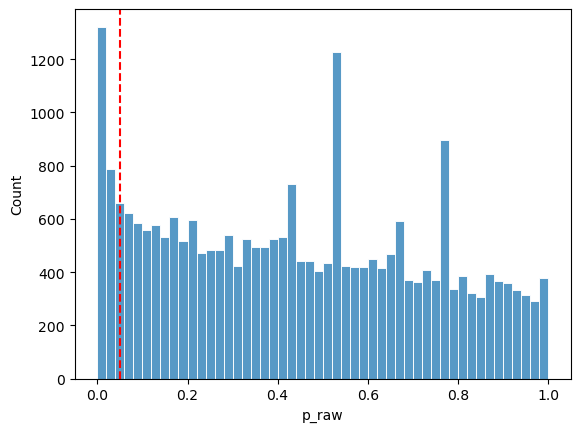

In [25]:
ax = sns.histplot(results_df['p_raw'], bins=50, edgecolor='white');
ax.axvline(0.05, color='red', linestyle='--');

# Number of genes with P < 0.05
print(f'Number of genes with P < 0.05 = {len(results_df.query("p_raw < 0.05"))}')

The distribution of raw *P* values is fairly flat. There are a couple of odd peaks around 0.5 and 0.65 which are not of interest. 

The distribution peaks below 0.05. This peak is made up of (1) genes that are differentially expressed when treated with dexamethasone, and of (2) false positive genes that are not differentially expressed, but whose read counts by chance result in *P* < 0.05.

There ae 2,432 such genes.

## Adjust raw *P*-values using the Benjamini-Hochberg method

We now convert the raw *P*-values from the 25,403 *t*-tests into adjusted *P*-values using the Benjamini-Hochberg method. The results are saved in the DataFrame.

In [28]:

# send the raw p-values for adjustment using the Benjamini-Hochberg method
# and save the adjusted p-values into a new column in the dataframe
results_df['p_adj'] = multipletests(results_df['p_raw'], method='fdr_bh')[1]

# print the dataframe of raw and adjusted p-values sorted on ascending adjusted p-value
results_df.sort_values('p_adj')

,gene_id,p_raw,p_adj
4729,E122877,0.000011,0.028547
291,E013297,0.000009,0.028547
13575,E187193,0.000015,0.028547
24138,E267683,0.000012,0.028547
6027,E134253,0.000005,0.028547
...,...,...,...
14958,E203863,1.000000,1.000000
4742,E123066,0.995774,1.000000
15046,E204310,0.993898,1.000000
14552,E198483,0.991964,1.000000


### Plot a histogram of adjusted *P* values

Do a quick check to make sure the adjustment for multiple testing has worked.

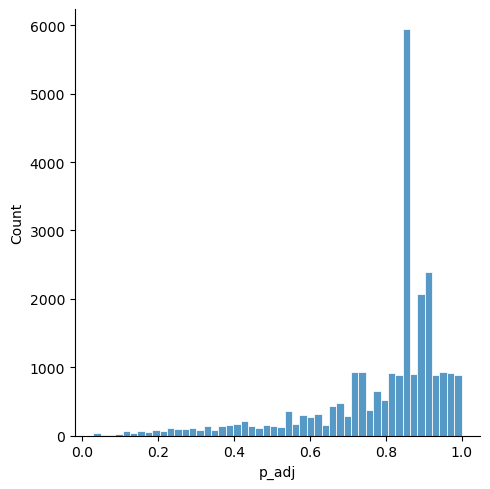

In [31]:
sns.displot(results_df['p_adj'], bins=50, edgecolor='white');

### Plot *P*<sub>raw</sub> against *P*<sub>adj</sub>

It is instructive to see what the Benjamini-Hochberg method does to *P* values. Raw *P*-values are plotted against adjusted *P*-values in the plot below. The blue dots are genes that have raw *P*-values above 0.05 so are of no interest. The orange dots are genes that have significant raw *P*-values below 0.05 but the Benjamini-Hochberg method has pushed their adjusted *P*-value upward, above 0.05, to non-significance. That leaves the few genes in orange that have very small significant raw *P*-values and also significant adjusted *P*-values. These are the genes that are of interest to the researchers.

<div class="alert alert-info">

Note: This kind of plot should **not** go in a poster. It is just here to demonstrate what the Benjamini-Hochberg method does to *P*-values.
</div>

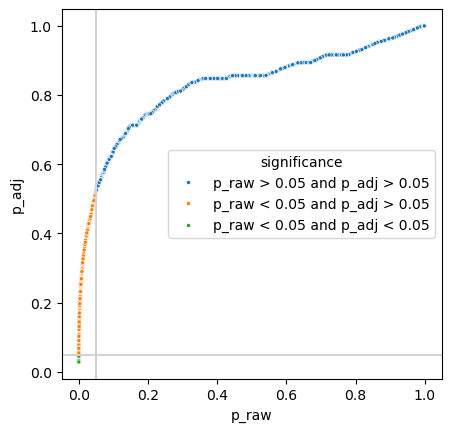

In [33]:
def label(row):
    """ return a string on whether p_raw and p_adj are greater or less than 0.05 """
    return f"p_raw {'<' if row['p_raw'] < 0.05 else '>'} 0.05 and p_adj {'<' if row['p_adj'] < 0.05 else '>'} 0.05"

results_df['significance'] = results_df.apply(lambda row: label(row), axis=1)

ax = sns.scatterplot(data=results_df, x='p_raw', y='p_adj', hue='significance', marker='.')
ax.set_aspect('equal')
ax.axvline(0.05, ls='-', color='LightGrey')
ax.axhline(0.05, ls='-', color='LightGrey');

## Print out the genes with significant adjusted *P* values

In [35]:
discoveries = results_df.query('p_adj < 0.05').sort_values('p_adj')
print(len(discoveries))
discoveries

34


,gene_id,p_raw,p_adj,significance
291,E013297,0.000009,0.028547,p_raw < 0.05 and p_adj < 0.05
13575,E187193,0.000015,0.028547,p_raw < 0.05 and p_adj < 0.05
11471,E173110,0.000014,0.028547,p_raw < 0.05 and p_adj < 0.05
8664,E155962,0.000006,0.028547,p_raw < 0.05 and p_adj < 0.05
8347,E152583,0.000003,0.028547,p_raw < 0.05 and p_adj < 0.05
7378,E143494,0.000007,0.028547,p_raw < 0.05 and p_adj < 0.05
6027,E134253,0.000005,0.028547,p_raw < 0.05 and p_adj < 0.05
5284,E128285,0.000012,0.028547,p_raw < 0.05 and p_adj < 0.05
4729,E122877,0.000011,0.028547,p_raw < 0.05 and p_adj < 0.05
24138,E267683,0.000012,0.028547,p_raw < 0.05 and p_adj < 0.05


The Benjamini-Hochberg method says that, of all the significant genes discovered (the ones printed above), on average 5% of them are expected to be false positives. 

There are 34 discovered genes. 5% of that is 1.7 genes. So we might expect of all the genes listed, 1 or 2 of them are false positives.

That is much better than using the raw *P*-values which gave us 2,432 genes with significantly changed expression. 

## Volcano plot (raw *P*-value against log-fold change)

Scientists have invented the volcano plot to illustrate the relationship between the expression of genes against their statistical significance. 

The first step in producing this plot is to calculate the mean log2-fold change in expression of each gene. What is log2-fold change?

Let's look at an example. Say dexamethasone doubled the expression of a gene on average. So the mean RNA short read count of the treated cells (let's call it $\mu_\text{trt}$) would be double the the mean RNA short read count of the untreated cells (let's call it $\mu_\text{untrt}$), i.e.,

$$\mu_\text{trt} = 2 \mu_\text{untrt}$$

In other words, there is a 2-fold increase in RNA short read counts between treated and untreated cells, i.e., 

$$\text{fold change} = \frac{\mu_\text{trt}}{\mu_\text{untrt}} = 2$$

Now we take log base 2 to get the log2-fold change:

$$\log_2 \text{fold change} = \log_2 2 = 1$$

So a doubling of expression gives a log2-fold change of 1. A quadrupling of expression gives a log2-fold change of 2, and so on.

If, on the other hand, dexamethasone halves the expression of a gene we have:

$$\text{fold change} = \frac{\mu_\text{trt}}{\mu_\text{untrt}} = \frac{1}{2}$$

And a log2-fold change of -1:

$$\log_2 \text{fold change} = \log_2 \frac{1}{2} = -1$$

This is the reason why we calculated and used log base 2 read counts in the *t*-tests.
 
The following code calculates the log2-fold change in mean RNA short read counts for each gene and stores it in our results DataFrame.

In [38]:
# storage for log2-fold change for each gene
log2fc = []

# loop through all genes
for gene_id, gene in genes:

    # get the log2 counts for the four treated and the four untreated cell lines
    trt_counts = gene[gene['dex'] == 'treated']['log count']
    untrt_counts = gene[gene['dex'] == 'untreated']['log count']

    # Calculate the means of the log2 counts for treated and untreated cell lines
    mean_trt = trt_counts.mean()
    mean_untrt = untrt_counts.mean()

    # calculate the log2 fold change and save
    log2fc.append( mean_trt - mean_untrt )

# add the log2 fold change results to the DataFrame
results_df['log2fc'] = log2fc
results_df

,gene_id,p_raw,p_adj,significance,log2fc
0,E000003,0.154514,0.713029,p_raw > 0.05 and p_adj > 0.05,-0.560669
1,E000419,0.925824,0.972746,p_raw > 0.05 and p_adj > 0.05,0.026035
2,E000457,0.527302,0.856147,p_raw > 0.05 and p_adj > 0.05,-0.142602
3,E000460,0.443651,0.856147,p_raw > 0.05 and p_adj > 0.05,-0.237710
4,E000971,0.598771,0.881235,p_raw > 0.05 and p_adj > 0.05,0.245273
...,...,...,...,...,...
25398,E273477,0.698030,0.907591,p_raw > 0.05 and p_adj > 0.05,0.205674
25399,E273483,0.473038,0.856147,p_raw > 0.05 and p_adj > 0.05,0.494320
25400,E273486,0.510124,0.856147,p_raw > 0.05 and p_adj > 0.05,-0.328961
25401,E273487,0.029086,0.428529,p_raw < 0.05 and p_adj > 0.05,0.784376


Volcano plots show raw *P* value against log2-fold change. However there's a problem with the raw *P* values because they can be tiny, like 10<sup>-6</sup>, and also close to 1. So plotting raw *P* values will hide the interesting significant genes which have tiny values. To overcome this, the volcano plot uses log base 10 raw *P* values instead. So a raw *P* of 10<sup>-6</sup> is converted to -6. And a raw *P* close to 1 is converted to close to 0. Also the negative sign is removed by taking the negative log base 10 raw *P* value.

The code below shows how to do this.

In [40]:
results_df['-log10_p_raw'] = -np.log10(results_df['p_raw'])

Finally we add some additional information to the DataFrame so that the significant genes can be highlighted.

In [42]:
results_df['significant'] = results_df['p_adj'] < 0.05
results_df['significant'] = results_df['significant'].replace({True: 'yes', False: 'no'})
results_df

,gene_id,p_raw,p_adj,significance,log2fc,-log10_p_raw,significant
0,E000003,0.154514,0.713029,p_raw > 0.05 and p_adj > 0.05,-0.560669,0.811032,no
1,E000419,0.925824,0.972746,p_raw > 0.05 and p_adj > 0.05,0.026035,0.033472,no
2,E000457,0.527302,0.856147,p_raw > 0.05 and p_adj > 0.05,-0.142602,0.277940,no
3,E000460,0.443651,0.856147,p_raw > 0.05 and p_adj > 0.05,-0.237710,0.352959,no
4,E000971,0.598771,0.881235,p_raw > 0.05 and p_adj > 0.05,0.245273,0.222739,no
...,...,...,...,...,...,...,...
25398,E273477,0.698030,0.907591,p_raw > 0.05 and p_adj > 0.05,0.205674,0.156126,no
25399,E273483,0.473038,0.856147,p_raw > 0.05 and p_adj > 0.05,0.494320,0.325104,no
25400,E273486,0.510124,0.856147,p_raw > 0.05 and p_adj > 0.05,-0.328961,0.292325,no
25401,E273487,0.029086,0.428529,p_raw < 0.05 and p_adj > 0.05,0.784376,1.536317,no


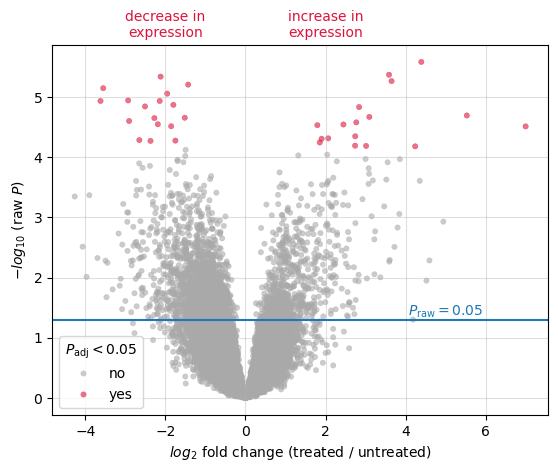

In [43]:
ax = sns.scatterplot(
    data=results_df,
    x='log2fc',
    y='-log10_p_raw',
    hue='significant',
    palette={'yes': 'crimson', 'no': 'darkgray'},
    alpha=0.6,
    edgecolor=None,
    s=15
)

ax.set_xlabel('$log_2$ fold change (treated / untreated)')
ax.set_ylabel('$-log_{10}$ (raw $P$)')
ax.legend(title=r'$P_\text{adj} < 0.05$')
ax.axhline(-np.log10(0.05))
ax.text(5, -np.log10(0.05), r'$P_\text{raw}=0.05$', ha='center', va='bottom', color='C0');
ax.text(2, 6, 'increase in\nexpression', ha='center', color='crimson')
ax.text(-2, 6, 'decrease in\nexpression', ha='center', color='crimson');
ax.grid(True, alpha=0.4)


Each dot in the volcano plot is a gene. Genes to the right have a positive log2-fold change (increased expression), genes to the left have a negative log2-fold change (decreased expression). 

Genes whose log2-fold change are statistically significantly different from zero, after correction for multiple testing, are shown in red at the top. 

The raw *P*-value of 0.05 is shown as the horizontal blue line.

---

# How the dataset was cleaned

The original dataset was very large with lots of unnecessary information and genes that had identical means in the treated and untreated cell lines (often genes with all counts equal to zero). If you're interested, here is how it was cleaned. 

In [47]:
full = pd.read_csv("../Datasets/airway_merged_data_full.csv")
full

,Gene_ID,dex,Sample_ID,Count
0,ENSG00000000003,untrt,SRR1039508,679
1,ENSG00000000005,untrt,SRR1039508,0
2,ENSG00000000419,untrt,SRR1039508,467
3,ENSG00000000457,untrt,SRR1039508,260
4,ENSG00000000460,untrt,SRR1039508,60
...,...,...,...,...
509411,ENSG00000273489,trt,SRR1039521,0
509412,ENSG00000273490,trt,SRR1039521,0
509413,ENSG00000273491,trt,SRR1039521,0
509414,ENSG00000273492,trt,SRR1039521,0


In [48]:
# change column names to lowercase and rename Sample_ID to cell_line
full.columns = ['gene_id', 'dex', 'cell_line', 'count']

# In "dex" column replace "untrt" with "untreated" and "trt" with "treated" to make it clearer
full['dex'] = full['dex'].replace({'untrt':'untreated', 'trt':'treated'})

full

,gene_id,dex,cell_line,count
0,ENSG00000000003,untreated,SRR1039508,679
1,ENSG00000000005,untreated,SRR1039508,0
2,ENSG00000000419,untreated,SRR1039508,467
3,ENSG00000000457,untreated,SRR1039508,260
4,ENSG00000000460,untreated,SRR1039508,60
...,...,...,...,...
509411,ENSG00000273489,treated,SRR1039521,0
509412,ENSG00000273490,treated,SRR1039521,0
509413,ENSG00000273491,treated,SRR1039521,0
509414,ENSG00000273492,treated,SRR1039521,0


In [49]:
# remove genes that have identical mean counts between treated and untreated samples
# as these have zero differential expression and will not be informative for downstream analysis

def filter_equal_counts(group):
    """ return True if means are different and False if they are the same """
    treated_counts = group[group['dex'] == 'treated']['count']
    untreated_counts = group[group['dex'] == 'untreated']['count']
    return not treated_counts.mean() == untreated_counts.mean()

cleaned_1 = full.groupby('gene_id').filter(lambda x: filter_equal_counts(x))
cleaned_1

,gene_id,dex,cell_line,count
0,ENSG00000000003,untreated,SRR1039508,679
2,ENSG00000000419,untreated,SRR1039508,467
3,ENSG00000000457,untreated,SRR1039508,260
4,ENSG00000000460,untreated,SRR1039508,60
5,ENSG00000000938,untreated,SRR1039508,0
...,...,...,...,...
509409,ENSG00000273487,treated,SRR1039521,10
509410,ENSG00000273488,treated,SRR1039521,14
509411,ENSG00000273489,treated,SRR1039521,0
509414,ENSG00000273492,treated,SRR1039521,0


That removed about 250,000 rows from the dataset.

In [51]:
# remove genes that have every count identical in either treatment, as these will have zero variability

def filter_identical_counts(group):
    """ return False if counts are all the same in either the treated or untreated cell lines, otherwise return True """
    treated_counts = group[group['dex'] == 'treated']['count']
    untreated_counts = group[group['dex'] == 'untreated']['count']
    return not (treated_counts.nunique() == 1 or untreated_counts.nunique() == 1)

cleaned_2 = cleaned_1.groupby('gene_id').filter(lambda x: filter_identical_counts(x))
cleaned_2

,gene_id,dex,cell_line,count
0,ENSG00000000003,untreated,SRR1039508,679
2,ENSG00000000419,untreated,SRR1039508,467
3,ENSG00000000457,untreated,SRR1039508,260
4,ENSG00000000460,untreated,SRR1039508,60
6,ENSG00000000971,untreated,SRR1039508,3251
...,...,...,...,...
509399,ENSG00000273477,treated,SRR1039521,12
509405,ENSG00000273483,treated,SRR1039521,6
509408,ENSG00000273486,treated,SRR1039521,11
509409,ENSG00000273487,treated,SRR1039521,10


That removed about 50,000 rows.

In [53]:
# calculate and check the distribution of raw p-values
cleaned_2['log count'] = np.log2(cleaned_2['count'] + 1)
genes = cleaned_2.groupby('gene_id')
p_raw = []

for gene_id, gene in genes:
    trt_counts = gene[gene['dex'] == 'treated']['log count']
    untrt_counts = gene[gene['dex'] == 'untreated']['log count']
    test = ttest_ind(trt_counts, untrt_counts)
    p_raw.append(ttest_ind(trt_counts, untrt_counts).pvalue)


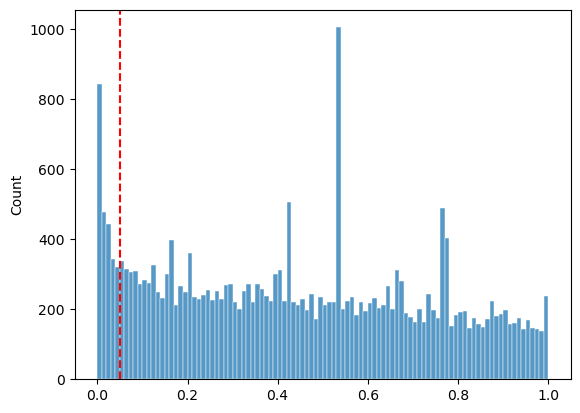

In [54]:
ax = sns.histplot(p_raw, bins=100, edgecolor='white');
ax.axvline(0.05, color='red', linestyle='--');

In [55]:
cleaned_2.head(8)

,gene_id,dex,cell_line,count,log count
0,ENSG00000000003,untreated,SRR1039508,679,9.409391
2,ENSG00000000419,untreated,SRR1039508,467,8.870365
3,ENSG00000000457,untreated,SRR1039508,260,8.027906
4,ENSG00000000460,untreated,SRR1039508,60,5.930737
6,ENSG00000000971,untreated,SRR1039508,3251,11.667112
7,ENSG00000001036,untreated,SRR1039508,1433,10.485829
8,ENSG00000001084,untreated,SRR1039508,519,9.022368
9,ENSG00000001167,untreated,SRR1039508,394,8.625709


In [56]:
# Sort by gene_id then dex then cell_line
cleaned_3 = cleaned_2.sort_values(['gene_id', 'dex', 'cell_line']).reset_index(drop=True)

# remove characters from gene_id and cell_line that occur in the same position in all values
# this will reduce the size of the csv file
cleaned_3['gene_id'] = 'E' + cleaned_3['gene_id'].str[-6:]
cleaned_3['cell_line'] = 'S' + cleaned_3['cell_line'].str[-2:]

cleaned_3.head(16)

,gene_id,dex,cell_line,count,log count
0,E000003,treated,S09,448,8.810572
1,E000003,treated,S13,408,8.675957
2,E000003,treated,S17,1047,10.033423
3,E000003,treated,S21,572,9.162391
4,E000003,untreated,S08,679,9.409391
5,E000003,untreated,S12,873,9.771489
6,E000003,untreated,S16,1138,10.153552
7,E000003,untreated,S20,770,9.590587
8,E000419,treated,S09,515,9.011227
9,E000419,treated,S13,365,8.515700


In [57]:
# save cleaned dataset to a new csv file, remove log count
cleaned_3[['gene_id', 'dex', 'cell_line', 'count']].to_csv('../Datasets/airway_merged_data_cleaned.csv', index=False)